In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
def check_null_summary(df: pd.DataFrame) -> pd.DataFrame:
    total_rows = df.shape[0]  # Sử dụng shape để lấy số dòng
    null_counts = df.isnull().sum()
    null_percent = (null_counts / total_rows * 100).round(2)
    null_summary = pd.DataFrame({
        'null_count': null_counts,
        'null_percent': null_percent
    })
    null_summary = null_summary.sort_values('null_count', ascending=False)
    return null_summary

In [3]:
from google.colab import drive
root_drive='/content/drive'
drive.mount(root_drive, force_remount=True)

Mounted at /content/drive


In [4]:
df = pd.read_csv('/content/drive/MyDrive/KhoaLuan/Data/df_reduced.csv', nrows = None)

In [5]:
df.shape

(338857, 28)

In [6]:
df.columns

Index(['TARGET', 'EXT_SOURCE_MEAN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT',
       'AMT_ANNUITY', 'BURO_AMT_CREDIT_SUM_DEBT_MEAN', 'BURO_DAYS_CREDIT_MEAN',
       'BURO_DAYS_CREDIT_ENDDATE_MEAN', 'BURO_AMT_CREDIT_SUM_MEAN',
       'BURO_AMT_CREDIT_MAX_OVERDUE_MEAN', 'BURO_DAYS_CREDIT_UPDATE_MEAN',
       'PREV_AMT_ANNUITY_MEAN', 'PREV_CNT_PAYMENT_SUM',
       'PREV_APP_CREDIT_PERC_MIN', 'PREV_DAYS_DECISION_MAX', 'INST_DPD_MEAN',
       'INST_PAYMENT_DIFF_MEAN', 'INST_AMT_PAYMENT_MEAN',
       'INST_DAYS_ENTRY_PAYMENT_MAX', 'INST_AMT_INSTALMENT_MAX',
       'POS_MONTHS_BALANCE_SIZE', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
       'ORGANIZATION_TYPE', 'NAME_FAMILY_STATUS', 'DAYS_ID_PUBLISH',
       'DAYS_REGISTRATION', 'DAYS_LAST_PHONE_CHANGE'],
      dtype='object')

In [7]:
df['TARGET'].value_counts()

,count
TARGET,
0.0,267212
1.0,23845


In [20]:
import plotly.express as px

# Đếm số lượng từng giá trị trong TARGET
target_counts = df['TARGET'].value_counts().reset_index()
target_counts.columns = ['TARGET', 'Count']

# Đổi nhãn nếu cần (ví dụ 0: không vỡ nợ, 1: vỡ nợ)
target_counts['TARGET'] = target_counts['TARGET'].map({0: 'No Default', 1: 'Default'})

# Vẽ donut chart
fig = px.pie(
    target_counts,
    values='Count',
    names='TARGET',
    title="Loan Default Distribution",
    hole=0.5,
    color_discrete_sequence=px.colors.qualitative.Set2
)

# Tùy chỉnh hiển thị phần trăm trong hình tròn
fig.update_traces(
    textinfo='percent',
    textposition='inside',
    insidetextorientation='radial'
)

# Layout sạch sẽ
fig.update_layout(
    showlegend=True,
    legend_title_text='Loan Status',
    font=dict(size=14),
    plot_bgcolor='rgba(0,0,0,0)',
    paper_bgcolor='rgba(255,255,255,1)',
)

fig.show()


In [ ]:
check_null_summary(df)

,null_count,null_percent
TARGET,47800,14.11
EXT_SOURCE_MEAN,0,0.00
AMT_INCOME_TOTAL,0,0.00
AMT_CREDIT,0,0.00
AMT_ANNUITY,0,0.00
BURO_AMT_CREDIT_SUM_DEBT_MEAN,0,0.00
BURO_DAYS_CREDIT_MEAN,0,0.00
BURO_DAYS_CREDIT_ENDDATE_MEAN,0,0.00
BURO_AMT_CREDIT_SUM_MEAN,0,0.00
BURO_AMT_CREDIT_MAX_OVERDUE_MEAN,0,0.00


In [8]:
df = df[df['TARGET'].notnull()]

In [10]:
df.shape

(291057, 28)

In [11]:
df['NAME_FAMILY_STATUS'].value_counts()

,count
NAME_FAMILY_STATUS,
Married,186302
Single / not married,42220
Civil marriage,28339
Separated,18776
Widow,15420


In [12]:
df['ORGANIZATION_TYPE'].value_counts()

,count
ORGANIZATION_TYPE,
Business Entity Type 3,63963
XNA,52589
Self-employed,37083
Other,15829
Medicine,10682
Business Entity Type 2,9936
Government,9880
School,8534
Trade: type 7,7453


In [13]:
def group_organization_type(org):
    if pd.isna(org):
        return org
    org = org.lower()
    if "business entity" in org:
        return "Business Entity"
    elif "trade" in org:
        return "Trade"
    elif "industry" in org:
        return "Industry"
    elif "transport" in org:
        return "Transport"
    elif "security" in org:
        return "Security"
    elif "type" in org and "industry" not in org and "trade" not in org:
        return "Other Type"
    elif org in ["xna", "other"]:
        return "Unknown"
    elif "school" in org or "university" in org or "kindergarten" in org:
        return "Education"
    elif "police" in org or "military" in org or "ministries" in org:
        return "Government Services"
    elif "medicine" in org or "emergency" in org:
        return "Healthcare"
    elif "restaurant" in org or "hotel" in org:
        return "Hospitality"
    elif "electricity" in org or "telecom" in org or "mobile" in org or "postal" in org:
        return "Utilities"
    elif "insurance" in org or "bank" in org:
        return "Finance"
    elif "services" in org or "cleaning" in org or "realtor" in org or "legal" in org or "advertising" in org:
        return "Services"
    elif "agriculture" in org:
        return "Agriculture"
    elif "housing" in org:
        return "Housing"
    elif "religion" in org or "culture" in org:
        return "Culture & Religion"
    else:
        return "Other"

df["ORGANIZATION_TYPE"] = df["ORGANIZATION_TYPE"].apply(group_organization_type)


In [14]:
df["ORGANIZATION_TYPE"].value_counts()

,count
ORGANIZATION_TYPE,
Business Entity,79405
Unknown,68418
Other,53324
Education,16395
Industry,13558
Trade,12944
Healthcare,11210
Transport,8547
Security,4956


In [15]:
df['AMT_CREDIT'].value_counts()

,count
AMT_CREDIT,
450000.0,9214
675000.0,8318
225000.0,7715
180000.0,7138
270000.0,7086
...,...
1324962.0,1
1259671.5,1
752157.0,1


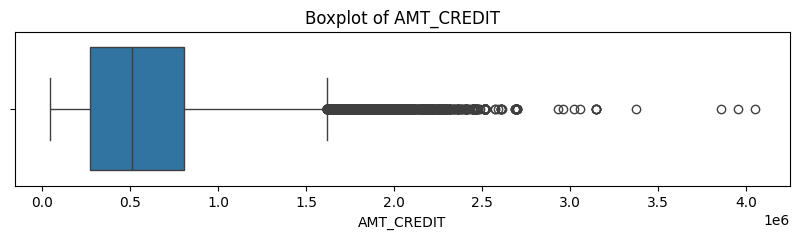

In [16]:

plt.figure(figsize=(10, 2))
sns.boxplot(x=df["AMT_CREDIT"])
plt.title("Boxplot of AMT_CREDIT")
plt.show()

In [ ]:
Q1 = df["AMT_CREDIT"].quantile(0.25)
Q3 = df["AMT_CREDIT"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["AMT_CREDIT"] < lower_bound) | (df["AMT_CREDIT"] > upper_bound)]
print("Số lượng outlier (IQR):", len(outliers))

Số lượng outlier (IQR): 5421


# Loại outlier

In [ ]:
df['AMT_ANNUITY'].value_counts()

,count
AMT_ANNUITY,
9000.0,6203
13500.0,5444
10125.0,1837
6750.0,1816
37800.0,1599
...,...
96264.0,1
44460.0,1
69529.5,1


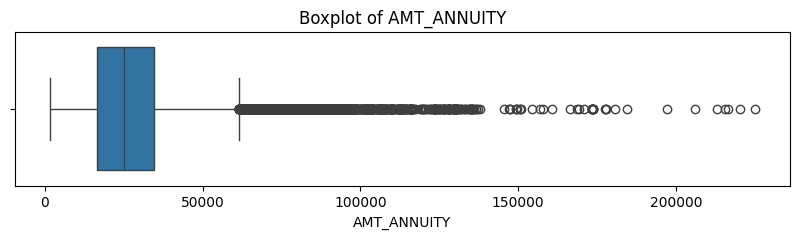

In [ ]:
plt.figure(figsize=(10, 2))
sns.boxplot(x=df["AMT_ANNUITY"])
plt.title("Boxplot of AMT_ANNUITY")
plt.show()

In [ ]:
Q1 = df["AMT_ANNUITY"].quantile(0.25)
Q3 = df["AMT_ANNUITY"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["AMT_ANNUITY"] < lower_bound) | (df["AMT_ANNUITY"] > upper_bound)]
print("Số lượng outlier (IQR):", len(outliers))

Số lượng outlier (IQR): 6276


In [ ]:
df['DAYS_BIRTH'].value_counts()

,count
DAYS_BIRTH,
-13481,41
-13749,41
-10020,39
-15771,39
-15565,38
...,...
-7489,1
-25020,1
-24865,1


In [ ]:
print("Giá trị nhỏ nhất (min):", df["DAYS_BIRTH"].min())
print("Giá trị lớn nhất (max):", df["DAYS_BIRTH"].max())
print("\nMô tả thống kê:")
print(df["DAYS_BIRTH"].describe())


Giá trị nhỏ nhất (min): -25201
Giá trị lớn nhất (max): -7489

Mô tả thống kê:
count    291057.000000
mean     -16050.902754
std        4355.796423
min      -25201.000000
25%      -19685.000000
50%      -15764.000000
75%      -12442.000000
max       -7489.000000
Name: DAYS_BIRTH, dtype: float64


In [ ]:
df["AGE"] = ((-df["DAYS_BIRTH"]) / 365).round().astype(int)

In [ ]:
print("Giá trị nhỏ nhất (min):", df["AGE"].min())
print("Giá trị lớn nhất (max):", df["AGE"].max())
print("\nMô tả thống kê:")
print(df["AGE"].describe())


Giá trị nhỏ nhất (min): 21
Giá trị lớn nhất (max): 69

Mô tả thống kê:
count    291057.000000
mean         43.976657
std          11.941582
min          21.000000
25%          34.000000
50%          43.000000
75%          54.000000
max          69.000000
Name: AGE, dtype: float64


In [ ]:
bins = [0, 25, 35, 45, 55, 65, 100]
labels = ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]
df["AGE_GROUP"] = pd.cut(df["AGE"], bins=bins, labels=labels, right=False)

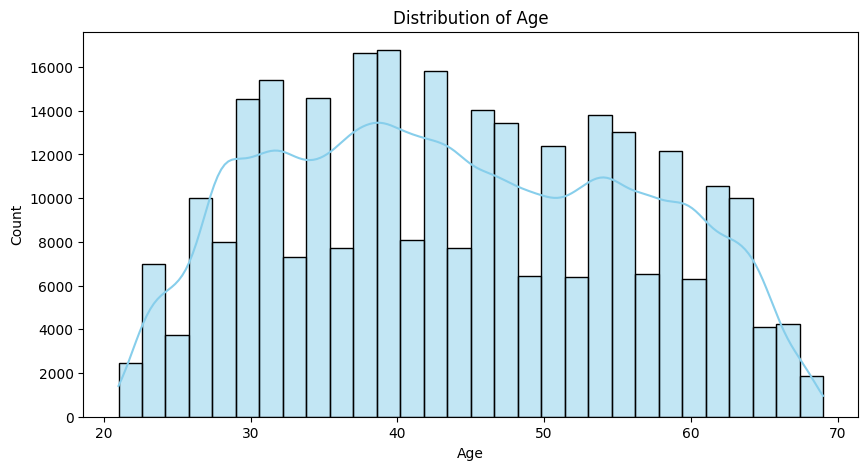

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(df["AGE"], bins=30, kde=True, color='skyblue')
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

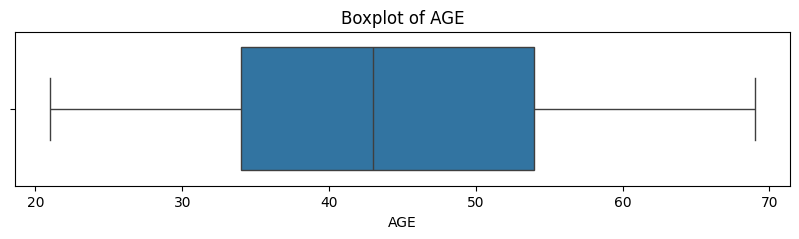

In [ ]:
plt.figure(figsize=(10, 2))
sns.boxplot(x=df["AGE"])
plt.title("Boxplot of AGE")
plt.show()

In [ ]:
Q1 = df["AGE"].quantile(0.25)
Q3 = df["AGE"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["AGE"] < lower_bound) | (df["AGE"] > upper_bound)]
print("Số lượng outlier (IQR):", len(outliers))

Số lượng outlier (IQR): 0


In [ ]:
print("Giá trị nhỏ nhất (min):", df["DAYS_REGISTRATION"].min())
print("Giá trị lớn nhất (max):", df["DAYS_REGISTRATION"].max())
print("\nMô tả thống kê:")
print(df["DAYS_REGISTRATION"].describe())


Giá trị nhỏ nhất (min): -24670.0
Giá trị lớn nhất (max): 0.0

Mô tả thống kê:
count    291057.000000
mean      -4994.775054
std        3518.469924
min      -24670.000000
25%       -7490.000000
50%       -4510.000000
75%       -2029.000000
max           0.000000
Name: DAYS_REGISTRATION, dtype: float64


In [ ]:
df["YEARS_REGISTRATION"] = (-df["DAYS_REGISTRATION"] / 365).round().astype(int)

In [ ]:
print("Giá trị nhỏ nhất (min):", df["YEARS_REGISTRATION"].min())
print("Giá trị lớn nhất (max):", df["YEARS_REGISTRATION"].max())
print("\nMô tả thống kê:")
print(df["YEARS_REGISTRATION"].describe())

Giá trị nhỏ nhất (min): 0
Giá trị lớn nhất (max): 68

Mô tả thống kê:
count    291057.000000
mean         13.683175
std           9.647168
min           0.000000
25%           6.000000
50%          12.000000
75%          21.000000
max          68.000000
Name: YEARS_REGISTRATION, dtype: float64


In [ ]:
print("Giá trị nhỏ nhất (min):", df["DAYS_ID_PUBLISH"].min())
print("Giá trị lớn nhất (max):", df["DAYS_ID_PUBLISH"].max())
print("\nMô tả thống kê:")
print(df["DAYS_ID_PUBLISH"].describe())

Giá trị nhỏ nhất (min): -7197
Giá trị lớn nhất (max): 0

Mô tả thống kê:
count    291057.000000
mean      -2992.268487
std        1510.500937
min       -7197.000000
25%       -4297.000000
50%       -3251.000000
75%       -1716.000000
max           0.000000
Name: DAYS_ID_PUBLISH, dtype: float64


In [ ]:
df["YEARS_ID_PUBLISH"] = (-df["DAYS_ID_PUBLISH"] / 365).round().astype(int)

In [ ]:
df["YEARS_ID_PUBLISH"].describe()

,YEARS_ID_PUBLISH
count,291057.000000
mean,8.193385
std,4.154441
min,0.000000
25%,5.000000
50%,9.000000
75%,12.000000
max,20.000000


In [ ]:
df['DAYS_EMPLOYED'].value_counts()

,count
DAYS_EMPLOYED,
365243,52589
-200,140
-224,138
-199,135
-212,132
...,...
-12543,1
-12853,1
-12027,1


In [ ]:
print("Giá trị nhỏ nhất (min):", df["DAYS_EMPLOYED"].min())
print("Giá trị lớn nhất (max):", df["DAYS_EMPLOYED"].max())
print("\nMô tả thống kê:")
print(df["DAYS_EMPLOYED"].describe())

Giá trị nhỏ nhất (min): -17912
Giá trị lớn nhất (max): 365243

Mô tả thống kê:
count    291057.000000
mean      64029.853458
std      141467.112622
min      -17912.000000
25%       -2772.000000
50%       -1230.000000
75%        -298.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64


In [ ]:
positive_count = df[df["DAYS_EMPLOYED"] > 0].shape[0]
print("Số giá trị dương trong DAYS_EMPLOYED:", positive_count)

Số giá trị dương trong DAYS_EMPLOYED: 52589


In [ ]:
negative_count = df[df["DAYS_EMPLOYED"] < 0].shape[0]
zero_count = df[df["DAYS_EMPLOYED"] == 0].shape[0]

print(f"Số giá trị âm: {negative_count}")
print(f"Số giá trị bằng 0: {zero_count}")


Số giá trị âm: 238466
Số giá trị bằng 0: 2


In [ ]:
df.loc[df["DAYS_EMPLOYED"] > 0, "DAYS_EMPLOYED"] = None


In [ ]:
df["YEARS_EMPLOYED"] = (-df["DAYS_EMPLOYED"] / 365).round().astype("float")


In [ ]:
df['AMT_INCOME_TOTAL'].value_counts()

,count
AMT_INCOME_TOTAL,
135000.0,34099
112500.0,29702
157500.0,25378
180000.0,23520
90000.0,21471
...,...
225112.5,1
107500.5,1
433350.0,1


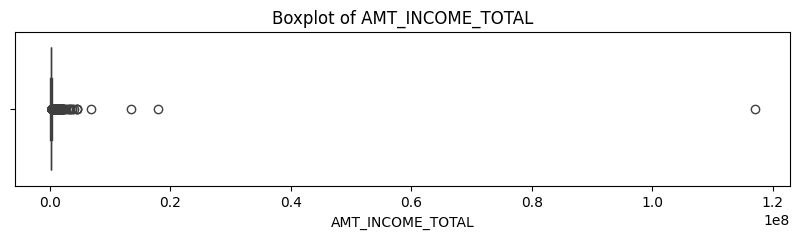

In [ ]:
plt.figure(figsize=(10, 2))
sns.boxplot(x=df["AMT_INCOME_TOTAL"])
plt.title("Boxplot of AMT_INCOME_TOTAL")
plt.show()

In [ ]:
Q1 = df["AMT_INCOME_TOTAL"].quantile(0.25)
Q3 = df["AMT_INCOME_TOTAL"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["AMT_INCOME_TOTAL"] < lower_bound) | (df["AMT_INCOME_TOTAL"] > upper_bound)]
print("Số lượng outlier (IQR):", len(outliers))

Số lượng outlier (IQR): 12328


In [ ]:
def group_organization_type(org):
    if pd.isna(org):
        return org
    org = org.lower()
    if "business entity" in org:
        return "Business Entity"
    elif "trade" in org:
        return "Trade"
    elif "industry" in org:
        return "Industry"
    elif "transport" in org:
        return "Transport"
    elif "security" in org:
        return "Security"
    elif "type" in org and "industry" not in org and "trade" not in org:
        return "Other Type"
    elif org in ["xna", "other"]:
        return "Unknown"
    elif "school" in org or "university" in org or "kindergarten" in org:
        return "Education"
    elif "police" in org or "military" in org or "ministries" in org:
        return "Government Services"
    elif "medicine" in org or "emergency" in org:
        return "Healthcare"
    elif "restaurant" in org or "hotel" in org:
        return "Hospitality"
    elif "electricity" in org or "telecom" in org or "mobile" in org or "postal" in org:
        return "Utilities"
    elif "insurance" in org or "bank" in org:
        return "Finance"
    elif "services" in org or "cleaning" in org or "realtor" in org or "legal" in org or "advertising" in org:
        return "Services"
    elif "agriculture" in org:
        return "Agriculture"
    elif "housing" in org:
        return "Housing"
    elif "religion" in org or "culture" in org:
        return "Culture & Religion"
    else:
        return "Other"

df["ORGANIZATION_TYPE"] = df["ORGANIZATION_TYPE"].apply(group_organization_type)

df['ORGANIZATION_TYPE'].value_counts()

,count
ORGANIZATION_TYPE,
Other,105223
Business Entity,79405
Unknown,53324
Industry,13558
Trade,12944
Transport,8547
Services,7487
Security,4956
Housing,2789


In [ ]:
df["NAME_FAMILY_STATUS"].value_counts()

,count
NAME_FAMILY_STATUS,
Married,186302
Single / not married,42220
Civil marriage,28339
Separated,18776
Widow,15420


In [21]:
def simplify_family_status(x):
    if x in ['Married', 'Civil marriage']:
        return 'Married'
    elif x == 'Single / not married':
        return 'Single'
    elif x in ['Separated', 'Widow']:
        return 'Not together'
    else:
        return 'Unknown'

df['NAME_FAMILY_STATUS'] = df['NAME_FAMILY_STATUS'].apply(simplify_family_status)


In [ ]:
import plotly.express as px

# Đếm số lượng từng giá trị trong TARGET
target_counts = df['NAME_FAMILY_STATUS'].value_counts().reset_index()
target_counts.columns = ['NAME_FAMILY_STATUS', 'Count']

# Đổi nhãn nếu cần (ví dụ 0: không vỡ nợ, 1: vỡ nợ)
target_counts['TARGET'] = target_counts['NAME_FAMILY_STATUS'].map({0: 'No Default', 1: 'Default'})

# Vẽ donut chart
fig = px.pie(
    target_counts,
    values='Count',
    names='TARGET',
    title="Loan Default Distribution",
    hole=0.5,
    color_discrete_sequence=px.colors.qualitative.Set2
)

# Tùy chỉnh hiển thị phần trăm trong hình tròn
fig.update_traces(
    textinfo='percent',
    textposition='inside',
    insidetextorientation='radial'
)

# Layout sạch sẽ
fig.update_layout(
    showlegend=True,
    legend_title_text='Loan Status',
    font=dict(size=14),
    plot_bgcolor='rgba(0,0,0,0)',
    paper_bgcolor='rgba(255,255,255,1)',
)

fig.show()


In [ ]:
df["YEARS_LAST_PHONE_CHANGE"] = (-df["DAYS_LAST_PHONE_CHANGE"] / 365).round().astype(int)
df["YEARS_LAST_PHONE_CHANGE"].value_counts()

,count
YEARS_LAST_PHONE_CHANGE,
1,56761
0,52816
2,47063
4,34465
3,32058
5,30923
6,16539
7,12493
8,4957


In [ ]:
df["BURO_DAYS_CREDIT_ENDDATE_MEAN_YEARS"] = (-df["BURO_DAYS_CREDIT_ENDDATE_MEAN"] / 365).round(1)
df["BURO_DAYS_CREDIT_MEAN_YEARS"] = (-df["BURO_DAYS_CREDIT_MEAN"] / 365).round(1)
df["BURO_DAYS_CREDIT_UPDATE_MEAN_YEARS"] = (-df["BURO_DAYS_CREDIT_UPDATE_MEAN"] / 365).round(1)
df["PREV_DAYS_DECISION_MAX_YEARS"] = (-df["PREV_DAYS_DECISION_MAX"] / 365).round(1)
df["INST_DAYS_ENTRY_PAYMENT_MAX_YEARS"] = (-df["INST_DAYS_ENTRY_PAYMENT_MAX"] / 365).round(1)


In [ ]:
drop_cols = [
    "DAYS_BIRTH", "DAYS_ID_PUBLISH", "DAYS_REGISTRATION", "DAYS_EMPLOYED",
    "DAYS_LAST_PHONE_CHANGE", "BURO_DAYS_CREDIT_ENDDATE_MEAN",
    "BURO_DAYS_CREDIT_MEAN", "BURO_DAYS_CREDIT_UPDATE_MEAN",
    "PREV_DAYS_DECISION_MAX", "INST_DAYS_ENTRY_PAYMENT_MAX"
]

df.drop(columns=drop_cols, inplace=True)

In [ ]:
# Kiểm tra missing values
check_null_summary(df)

,null_count,null_percent
YEARS_EMPLOYED,52589,18.07
EXT_SOURCE_MEAN,0,0.00
AMT_INCOME_TOTAL,0,0.00
AMT_CREDIT,0,0.00
TARGET,0,0.00
BURO_AMT_CREDIT_SUM_DEBT_MEAN,0,0.00
BURO_AMT_CREDIT_SUM_MEAN,0,0.00
BURO_AMT_CREDIT_MAX_OVERDUE_MEAN,0,0.00
PREV_AMT_ANNUITY_MEAN,0,0.00
PREV_CNT_PAYMENT_SUM,0,0.00


In [ ]:
df['YEARS_EMPLOYED'] = df['YEARS_EMPLOYED'].fillna(df['YEARS_EMPLOYED'].median())


In [ ]:
df.columns

Index(['TARGET', 'EXT_SOURCE_MEAN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT',
       'AMT_ANNUITY', 'BURO_AMT_CREDIT_SUM_DEBT_MEAN',
       'BURO_AMT_CREDIT_SUM_MEAN', 'BURO_AMT_CREDIT_MAX_OVERDUE_MEAN',
       'PREV_AMT_ANNUITY_MEAN', 'PREV_CNT_PAYMENT_SUM',
       'PREV_APP_CREDIT_PERC_MIN', 'INST_DPD_MEAN', 'INST_PAYMENT_DIFF_MEAN',
       'INST_AMT_PAYMENT_MEAN', 'INST_AMT_INSTALMENT_MAX',
       'POS_MONTHS_BALANCE_SIZE', 'ORGANIZATION_TYPE', 'NAME_FAMILY_STATUS',
       'AGE', 'AGE_GROUP', 'YEARS_REGISTRATION', 'YEARS_ID_PUBLISH',
       'YEARS_EMPLOYED', 'YEARS_LAST_PHONE_CHANGE',
       'BURO_DAYS_CREDIT_ENDDATE_MEAN_YEARS', 'BURO_DAYS_CREDIT_MEAN_YEARS',
       'BURO_DAYS_CREDIT_UPDATE_MEAN_YEARS', 'PREV_DAYS_DECISION_MAX_YEARS',
       'INST_DAYS_ENTRY_PAYMENT_MAX_YEARS'],
      dtype='object')

In [ ]:
df.head()

,TARGET,EXT_SOURCE_MEAN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_MAX_OVERDUE_MEAN,PREV_AMT_ANNUITY_MEAN,PREV_CNT_PAYMENT_SUM,...,AGE_GROUP,YEARS_REGISTRATION,YEARS_ID_PUBLISH,YEARS_EMPLOYED,YEARS_LAST_PHONE_CHANGE,BURO_DAYS_CREDIT_ENDDATE_MEAN_YEARS,BURO_DAYS_CREDIT_MEAN_YEARS,BURO_DAYS_CREDIT_UPDATE_MEAN_YEARS,PREV_DAYS_DECISION_MAX_YEARS,INST_DAYS_ENTRY_PAYMENT_MAX_YEARS
0,1.0,0.1617,202500.0,406597.5,24700.5,49156.2,108131.945,1681.0289,9251.775,24.0,...,25-34,10,6,2.0,3,1.0,2.4,1.4,1.7,0.1
1,0.0,0.4668,270000.0,1293502.5,35698.5,0.0,254350.120,0.0000,56553.990,30.0,...,45-54,3,1,3.0,2,1.5,3.8,2.2,2.0,1.5
2,0.0,0.6426,67500.0,135000.0,6750.0,0.0,94518.900,0.0000,5357.250,4.0,...,45-54,12,7,1.0,2,1.3,2.4,1.5,2.2,2.0
3,0.0,0.6504,135000.0,312682.5,29686.5,44971.6,194400.000,0.0000,23651.174,138.0,...,45-54,27,7,8.0,2,0.4,2.9,1.3,0.5,0.0
4,0.0,0.3228,121500.0,513000.0,21865.5,0.0,146250.000,0.0000,12278.805,124.0,...,55-64,12,9,8.0,3,2.1,3.1,2.1,1.0,0.0


In [ ]:
df.shape

(291057, 29)

In [ ]:
df.to_csv('/content/drive/MyDrive/KhoaLuan/Data/df_cleaned_old_customers.csv')